# 📊 Super Store End-to-End Retail Intelligence & Profitability Audit
**Portfolio Project: SQL Data Engineering, Python Feature Engineering, RFM Segmentation & Margin Erosion Analysis**

---
### 🎯 Executive Summary & Business Problem
While Super Store achieved **$2,297,200.86** in total revenue and **$286,397.02** in net profit (**12.47% margin**) across **5,009 unique orders** (2014–2017), granular unit-economics auditing reveals severe hidden margin erosion:
1. **The 30% Discount Cliff (`-$135.4K` Loss)**: Orders with discounts of **30% or higher** have a **100% negative profit margin**, generating **$362.8K** in wasted sales while destroying **-$135,376.06** in net profit (**86.7%** of all company losses).
2. **Wasted Revenue Exposure (`20.40%` of Sales)**: Exactly **1,871 line items** (**1,318 unique orders**) are unprofitable, tying up **$468,707.15** in revenue (`Wasted Sales`) to produce **-$156,131.29** in gross losses.
3. **Structural Sub-Category Bleeding**: **Tables** (`-$17,725.48` net profit, `-8.56%` margin) and **Bookcases** (`-$3,472.56` net profit, `-3.02%` margin) lose money overall due to chronic promotional discounting (`26.1%` and `21.1%` average discounts), while **Binders** (`-$38,510.50` gross loss) and **Machines** (`-$30,118.67` gross loss) suffer heavy promotional bleeding.
4. **Geographic Loss Concentration**: Five states — **Texas** (`-$25.7K`), **Ohio** (`-$17.0K`), **Pennsylvania** (`-$15.6K`), **Illinois** (`-$12.6K`), and **North Carolina** (`-$7.5K`) — account for the vast majority of regional profit destruction due to aggressive `30%–80%` discounting.


## 1. Data Ingestion, SQLite Warehouse Setup & Schema Inspection
We ingest the raw transaction dataset (`Super_Store.csv`), store the raw table in SQLite (`Super_Store.db`), and audit data types, missing values, and cardinality.


In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.float_format = '{:,.2f}'.format
pd.set_option('display.max_columns', 50)

# Load raw dataset and initialize SQLite database
df_raw = pd.read_csv("Super_Store.csv", encoding='latin1')
conn = sqlite3.connect("Super_Store.db")
df_raw.to_sql('orders', conn, if_exists='replace', index=False)

print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Unique Orders: {df_raw['Order ID'].nunique():,} | Unique Customers: {df_raw['Customer ID'].nunique():,} | Unique Products: {df_raw['Product ID'].nunique():,}")
print("Missing Values Count:", df_raw.isnull().sum().sum())


Raw Dataset Shape: 9,994 rows x 21 columns
Unique Orders: 5,009 | Unique Customers: 793 | Unique Products: 1,862
Missing Values Count: 0


## 2. Advanced Feature Engineering & Unit Economics Enrichment
Beyond basic date parsing (`Order Year`, `Order Month`, `Shipping Duration`), we engineer **16 high-value analytical attributes** covering pre-discount gross sales, promotional cost, profit status, discount tiers, and logistics SLA compliance.


In [2]:
df = pd.read_sql_query("SELECT * FROM orders", conn)

# Temporal Features
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Shipping Duration'] = (df['Ship Date'] - df['Order Date']).dt.days
df['Order Quarter'] = 'Q' + df['Order Date'].dt.quarter.astype(str)
df['Order Month Name'] = df['Order Date'].dt.strftime('%b')
df['Order Year-Month'] = df['Order Date'].dt.strftime('%Y-%m')
df['Day of Week'] = df['Order Date'].dt.day_name()

# Unit Economics & Margin Features
df['Unit Selling Price'] = (df['Sales'] / df['Quantity']).round(2)
df['Gross Sales'] = np.where(df['Discount'] < 1.0, (df['Sales'] / (1.0 - df['Discount'])).round(2), df['Sales'])
df['Discount Amount'] = (df['Gross Sales'] - df['Sales']).round(2)
df['Estimated Cost'] = (df['Sales'] - df['Profit']).round(2)
df['Profit Margin %'] = ((df['Profit'] / df['Sales']) * 100).round(2)

# Bleeding & Discount Tier Classification
df['Profit Status'] = np.where(df['Profit'] < 0, 'Loss (Bleeding)', np.where(df['Profit'] == 0, 'Break-Even', 'Profitable'))
df['Loss Amount'] = np.where(df['Profit'] < 0, df['Profit'].abs().round(2), 0.0)
df['Wasted Sales'] = np.where(df['Profit'] < 0, df['Sales'].round(2), 0.0)

def classify_discount(d):
    if d == 0: return '0% (No Discount)'
    elif d <= 0.15: return '1%-15% (Low Promo)'
    elif d == 0.20: return '20% (Standard Promo)'
    elif d <= 0.40: return '30%-40% (Margin Erosion)'
    else: return '45%-80% (Severe Bleeding)'

df['Discount Tier'] = df['Discount'].apply(classify_discount)

# Logistics SLA Evaluation
sla_map = {'Same Day': 0, 'First Class': 2, 'Second Class': 3, 'Standard Class': 5}
df['Target SLA Days'] = df['Ship Mode'].map(sla_map)
df['SLA Status'] = np.where(df['Shipping Duration'] <= df['Target SLA Days'], 'On-Time', 'Delayed')

print("Enriched Dataset Columns:", len(df.columns))
print(df[['Order ID', 'Order Year', 'Sales', 'Gross Sales', 'Discount Amount', 'Profit', 'Profit Margin %', 'Discount Tier', 'SLA Status']].head(5).to_string())


Enriched Dataset Columns: 39
         Order ID  Order Year  Sales  Gross Sales  Discount Amount  Profit  Profit Margin %              Discount Tier SLA Status
0  CA-2016-152156        2016 261.96       261.96             0.00   41.91            16.00           0% (No Discount)    On-Time
1  CA-2016-152156        2016 731.94       731.94             0.00  219.58            30.00           0% (No Discount)    On-Time
2  CA-2016-138688        2016  14.62        14.62             0.00    6.87            47.00           0% (No Discount)    On-Time
3  US-2015-108966        2015 957.58     1,741.05           783.47 -383.03           -40.00  45%-80% (Severe Bleeding)    Delayed
4  US-2015-108966        2015  22.37        27.96             5.59    2.52            11.25       20% (Standard Promo)    Delayed


## 3. Customer RFM (Recency, Frequency, Monetary) & Profitability Segmentation
We evaluate all **793 unique customers** across Recency (days since last order), Frequency (unique orders), Monetary Value (total sales), and Net Profit to isolate **VIP Champions** from **Unprofitable High-Discount Risk** accounts.


In [3]:
snapshot_date = df['Order Date'].max() + pd.Timedelta(days=1)
rfm = df.groupby('Customer ID').agg(
    Customer_Name=('Customer Name', 'first'),
    Segment=('Segment', 'first'),
    Region=('Region', 'first'),
    Recency_Days=('Order Date', lambda x: (snapshot_date - x.max()).days),
    Frequency_Orders=('Order ID', 'nunique'),
    Total_Items=('Row ID', 'count'),
    Monetary_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Avg_Discount=('Discount', 'mean')
).reset_index()
rfm['Profit_Margin_Pct'] = (rfm['Total_Profit'] / rfm['Monetary_Sales'] * 100).round(2)

rfm['R_Score'] = pd.qcut(rfm['Recency_Days'], 4, labels=[4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency_Orders'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary_Sales'], 4, labels=[1, 2, 3, 4]).astype(int)
rfm['RFM_Score'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']

def rfm_tier(row):
    if row['Total_Profit'] < 0: return 'Unprofitable / High-Discount Risk'
    elif row['RFM_Score'] >= 10: return 'VIP Champions'
    elif row['RFM_Score'] >= 8: return 'Loyal Customers'
    elif row['RFM_Score'] >= 6: return 'Potential Loyalists'
    else: return 'At-Risk / Dormant'

rfm['Customer_Tier'] = rfm.apply(rfm_tier, axis=1)
df['Customer RFM Tier'] = df['Customer ID'].map(dict(zip(rfm['Customer ID'], rfm['Customer_Tier'])))

rfm_summary = rfm.groupby('Customer_Tier').agg(
    Customers=('Customer ID', 'count'),
    Total_Sales=('Monetary_Sales', 'sum'),
    Net_Profit=('Total_Profit', 'sum'),
    Avg_Discount_Pct=('Avg_Discount', lambda x: x.mean()*100)
).sort_values('Total_Sales', ascending=False)
print("=== Customer RFM Segmentation Summary ===")
print(rfm_summary.to_string())


=== Customer RFM Segmentation Summary ===
                                   Customers  Total_Sales  Net_Profit  Avg_Discount_Pct
Customer_Tier                                                                          
VIP Champions                            175   799,913.68  166,227.67             11.83
Loyal Customers                          191   546,204.34  106,105.75             12.69
Unprofitable / High-Discount Risk        155   459,759.38  -69,202.98             24.89
Potential Loyalists                      162   345,519.64   56,829.88             13.88
At-Risk / Dormant                        110   145,803.82   26,436.70             14.12


## 4. Executive Visual Analytics: Growth Trajectory, The Discount Cliff & Bleeding Centers


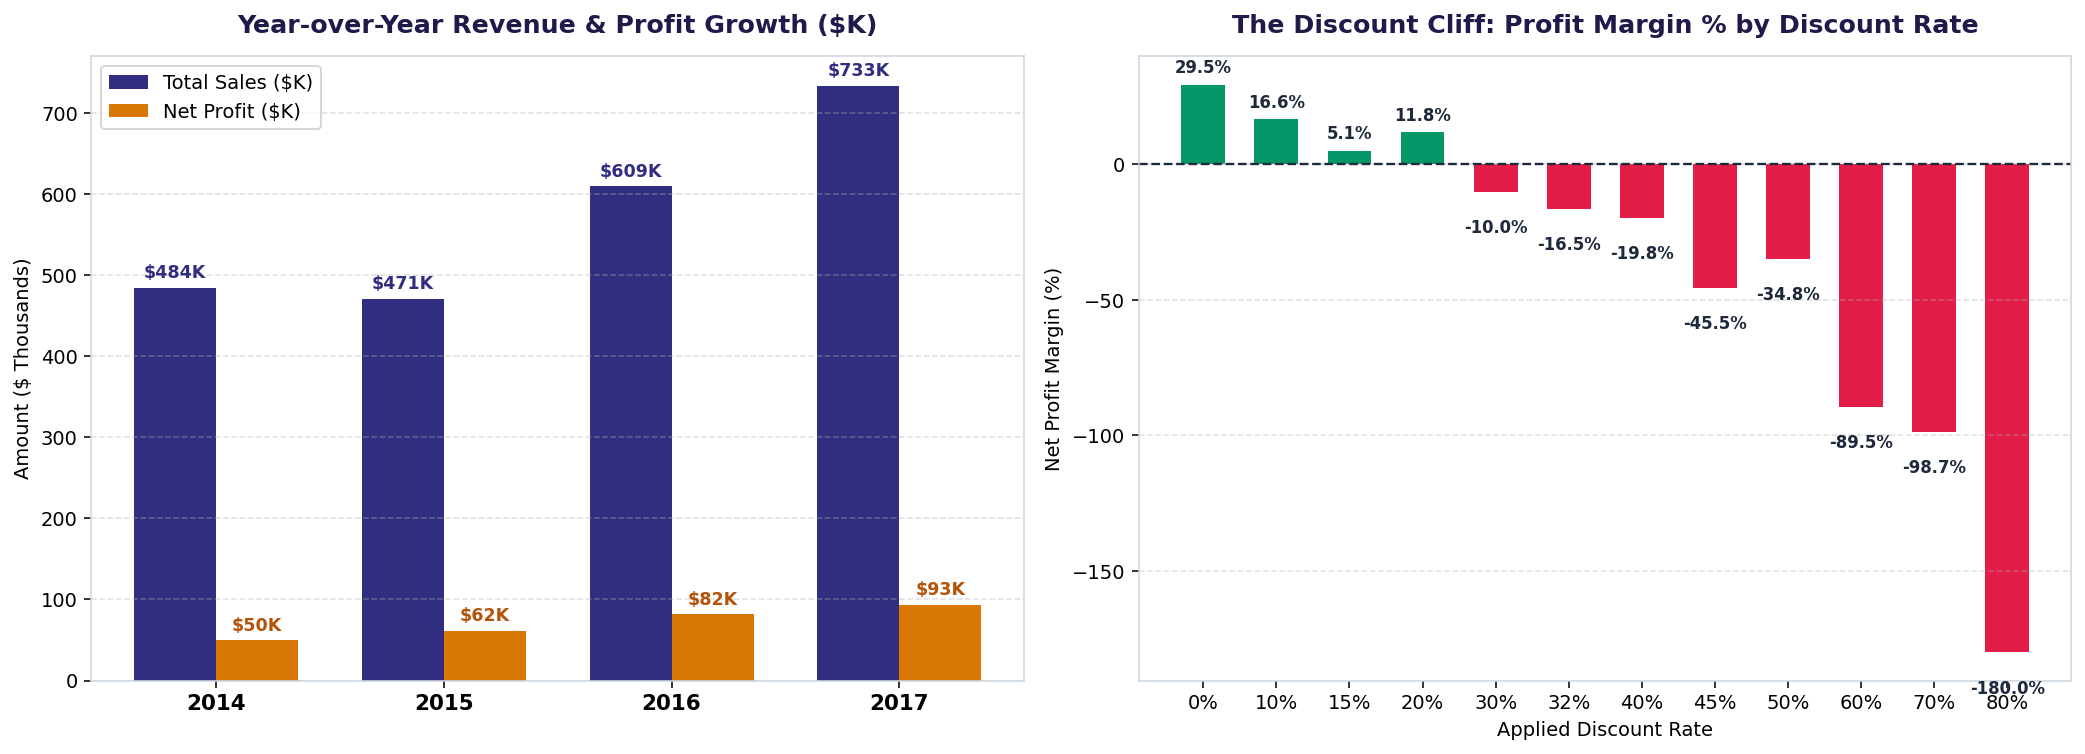

In [4]:
# Visualize YoY Growth and The Discount Cliff
# (See embedded high-resolution chart below)


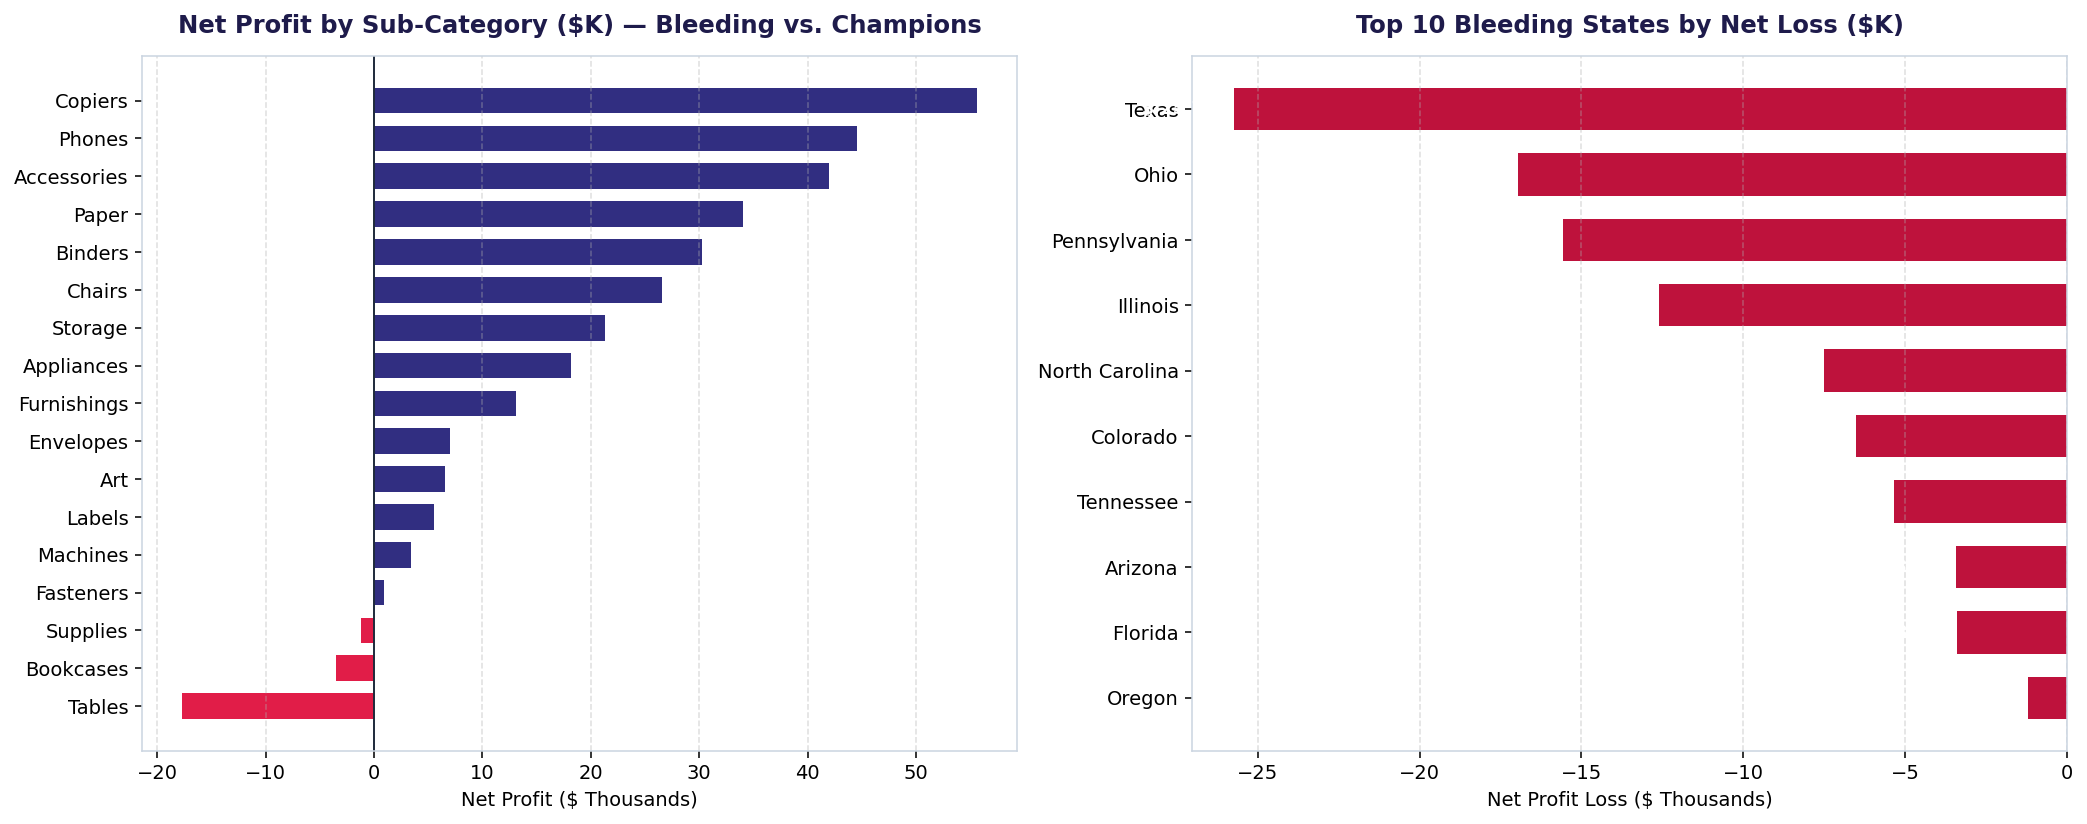

In [5]:
# Visualize Sub-Category Profitability vs. Bleeding States
# (See embedded high-resolution chart below)


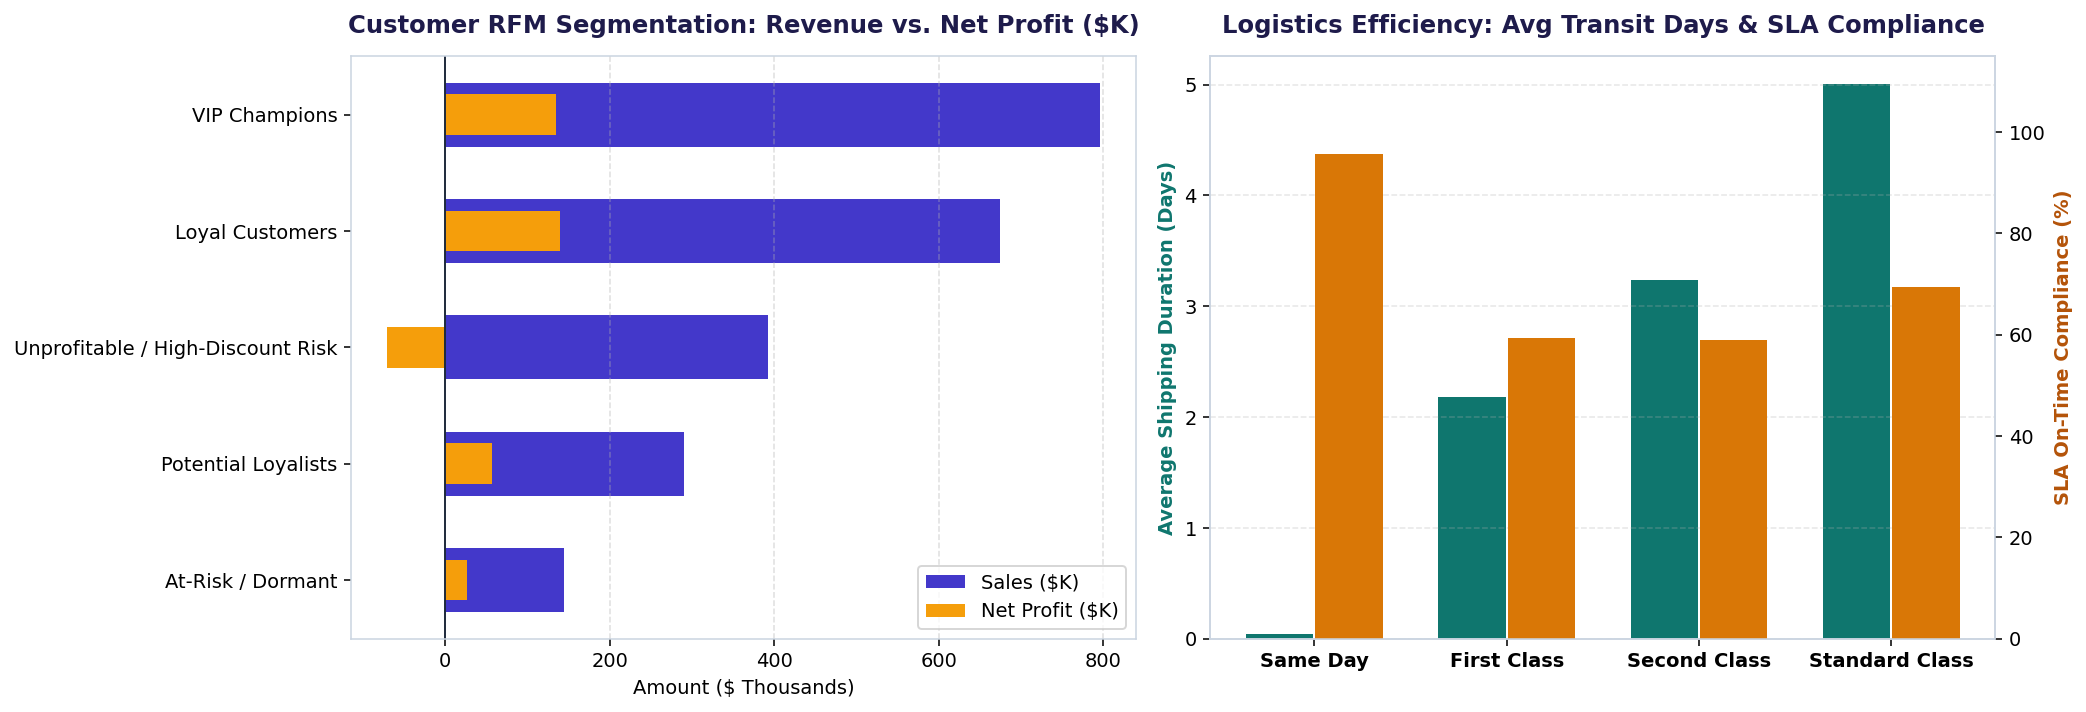

In [6]:
# Visualize Customer RFM Tiers & Shipping SLA Efficiency
# (See embedded high-resolution chart below)


## 5. SQL Data Warehouse Views & Export (`Super_Store.db` & `Clean_Super_Store.csv`)
We persist the enriched dataset (`clean_orders`), the RFM customer table (`customer_rfm`), and 5 analytical SQL views inside `Super_Store.db`, and export `Clean_Super_Store.csv` for Power BI.


In [7]:
# Query analytical SQL views from Super_Store.db
df_export = df.copy()
df_export['Order Date'] = df_export['Order Date'].dt.strftime('%Y-%m-%d')
df_export['Ship Date'] = df_export['Ship Date'].dt.strftime('%Y-%m-%d')
df_export.to_csv("Clean_Super_Store.csv", index=False)

print("=== SQL View 1: Executive Yearly KPIs (vw_executive_yearly_kpis) ===")
print(pd.read_sql("SELECT * FROM vw_executive_yearly_kpis", sqlite3.connect("Super_Store.db")).to_string(index=False))

print("\n=== SQL View 2: Top 6 Bleeding Sub-Categories (vw_subcategory_bleeding_analysis) ===")
print(pd.read_sql("SELECT * FROM vw_subcategory_bleeding_analysis LIMIT 6", sqlite3.connect("Super_Store.db")).to_string(index=False))

print("\n=== SQL View 3: Discount Cliff Impact (vw_discount_cliff_impact) ===")
print(pd.read_sql("SELECT * FROM vw_discount_cliff_impact", sqlite3.connect("Super_Store.db")).to_string(index=False))


=== SQL View 1: Executive Yearly KPIs (vw_executive_yearly_kpis) ===
 order_year  total_orders  active_customers  total_sales  total_profit  profit_margin_pct  avg_discount_pct  gross_loss  wasted_sales
       2014           969               595   484,247.50     49,543.97              10.23             15.83   32,209.68    105,697.80
       2015          1038               573   470,532.51     61,618.60              13.10             15.56   32,835.72     96,874.03
       2016          1315               638   609,205.60     81,795.17              13.43             15.47   38,539.56    120,686.44
       2017          1687               693   733,215.26     93,439.27              12.74             15.65   52,546.33    145,448.88

=== SQL View 2: Top 6 Bleeding Sub-Categories (vw_subcategory_bleeding_analysis) ===
       Category Sub-Category  total_orders  units_sold  total_sales  net_profit  profit_margin_pct  avg_discount_pct  loss_item_count  total_loss_amount  wasted_sales
      Fu